<div align="center"><img src="https://github.com/user-attachments/assets/5d3a38ab-b20c-4103-b401-cddc112bfac8" width="300" alt="NOVA IMS Logo">

  <br>
  <br>
  <b>Master in Data Science and Advanced Analytics</b>

  <b>Computational Intelligence for Optimization </b>

  2025–2026

  <h1><b> Vermeer’s <i>Girl with a pearl earing</i>: 100 triangles Challenge <b></h1>
</div>



### <span style="color:#89AC76;">C22_Natural_Selection | Members</span>

<table>
  <thead style="color:#89AC76;">
    <tr>
      <th>Name</th>
      <th>Student ID</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Afonso Hermenegildo</td>
      <td>20221958</td>
    </tr>
    <tr>
      <td>André Ferreira</td>
      <td>20250398</td>
    </tr>
    <tr>
      <td>Marco Martins</td>
      <td>20221951</td>
    </tr>
    <tr>
      <td>Maria Francisca Gonçalves</td>
      <td>20221942</td>
    </tr>
  </tbody>
</table>

## <span style="color:#89AC76;">Table of Contents</span>


[ADICIONAR!!]

---
<h2 id="chapter1" style="color:#89AC76;">1. Imports</h2>
<p><a href="#toc" style="color:#89AC76;"> Back to Table of Contents</a></p>

All libraries used throughout the notebook are imported here. We rely on `Pillow` and `numpy` for image handling, `matplotlib` for visualisation, and `scipy` for statistical testing. The class-provided `library` module is also imported to access the base `Solution` class.

In [1]:
import sys
sys.path.append('..')  # adjust if library lives elsewhere

import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from copy import deepcopy
from itertools import product
from typing import Callable
from tqdm import tqdm

from PIL import Image, ImageDraw
from scipy.stats import wilcoxon
from joblib import Parallel, delayed

# Functions
from triangle_sol import TriangleSolution

---
<h2 id="chapter2" style="color:#89AC76;">2. Target Image Loading &amp; Inspection</h2>
<p><a href="#toc" style="color:#89AC76;"> Back to Table of Contents</a></p>

We load the 300×400 target image and convert it to a NumPy array. Keeping the array in memory as a global constant avoids redundant I/O during fitness evaluations, which are called thousands of times per run.

In [2]:
# configuration
IMAGE_PATH   = 'girl_pearl_earing.png'  
IMG_WIDTH    = 300
IMG_HEIGHT   = 400
N_TRIANGLES  = 100

Image loaded: (300, 400) — array shape (400, 300, 4)


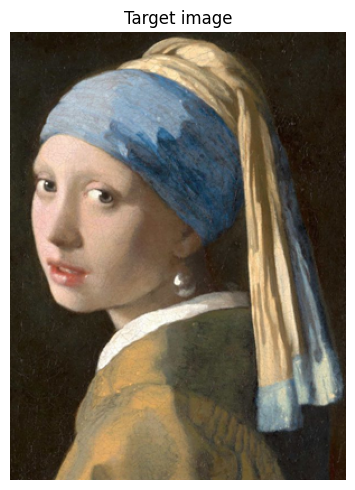

In [3]:
# load image
target_image = Image.open(IMAGE_PATH).convert('RGBA').resize((IMG_WIDTH, IMG_HEIGHT)) 
TARGET_ARRAY = np.array(target_image, dtype=np.int16)  # shape (400, 300, 4)
TriangleSolution.target_array = TARGET_ARRAY

print(f'Image loaded: {target_image.size} — array shape {TARGET_ARRAY.shape}')

plt.figure(figsize=(4, 5))

# Matplotlib handles RGBA arrays natively
plt.imshow(TARGET_ARRAY)
plt.title('Target image')
plt.axis('off')
plt.tight_layout()
plt.show()

---
<h2 id="chapter3" style="color:#89AC76;">3. Solution Representation</h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

### Representation - How the solution is encoded

Each individual in the population encodes a candidate image as an ordered sequence of **100 triangles**, drawn sequentially onto a 300×400 canvas — later triangles occlude earlier ones. Each triangle is represented by **10 real-valued genes**.

```
[ x1, y1, x2, y2, x3, y3, Red, Green, Blue, Alpha]
```


| Gene(s) | Variable | Domain |
|---|---|---|
| x₁, y₁, x₂, y₂, x₃, y₃ | Vertex coordinates | [0, 1] (normalised) |
| R, G, B | Fill colour | [0, 255] |
| A | Opacity | [0, 255] |

### Fitness - measurement of quality of the solution
Fitness is the **pixel-wise RMSE** between the rendered image and the target (lower is  better, since this is a minimisation problem):

$$\text{RMSE} = \sqrt{\frac{1}{W \cdot H \cdot 4} \sum_{i,j,c} (\hat{I}_{ijc} - I_{ijc})^2}$$

where $W=300$, $H=400$, and $C=4$ (RGBA channels)


<span style="color:#BA8E23;">

**TEXT ABOVE INSPIRED IN PRATICAL CLASS 3**

</span>

In [4]:
sol = TriangleSolution(
    n_triangles=N_TRIANGLES,
    img_width=IMG_WIDTH,
    img_height=IMG_HEIGHT,
    target_array=TARGET_ARRAY
)

In [5]:
sol.representation

array([ 23, 176, 168, 294, 107, 253,  53,  22, 196, 245,  47, 158, 270,
        10,  92,   1,  36, 225, 145, 251,  95, 303,  58, 292, 122, 292,
       254,  94, 223,  52, 209, 265, 286,  90,  89,   3, 157,  54, 237,
       179,  87,  66, 192, 309, 168, 170, 161,  83,  25, 107, 150, 164,
       210, 202, 147, 246, 255,  16, 242,  93, 259, 173, 105, 354, 272,
        45, 140,   6, 138,  92,   9, 134, 116, 247,  23, 333,  98, 166,
        38,  38, 213,  60, 221, 143, 249, 390, 221, 154, 103,   3,  44,
       246, 187,  28,  11, 386, 231,  27,  70, 164, 270, 133, 133,   5,
        93, 229, 118,  42, 216, 106, 167,  88, 297, 346,  32, 184, 228,
       219, 105, 227,  85, 102, 208, 390, 124,   7, 195, 131,  46, 134,
       132,  63,  83, 239, 113,   8,  43,  11,  82, 170, 195,  43, 116,
       370, 194, 262, 182, 120,  74,  75,  88,  96, 216, 132, 167, 355,
       157,   5, 146, 247, 234, 270,   6, 317,  67, 249, 135,  12, 216,
       200,  97, 132, 270, 345, 107,  66,  97,  38,  52,   7,   

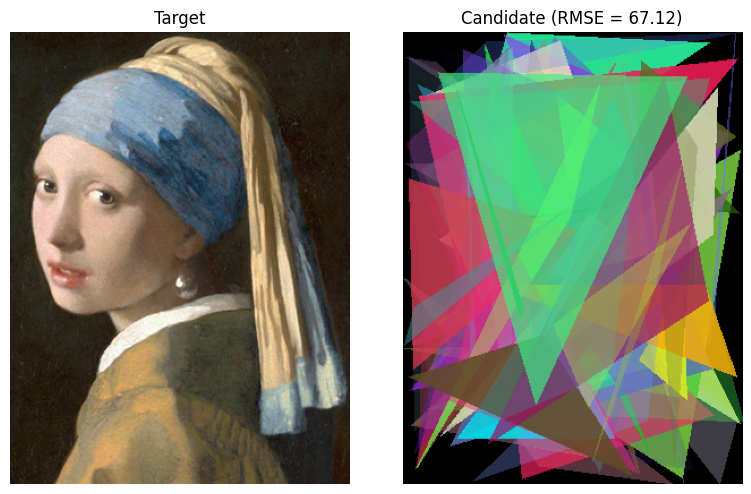

In [6]:
sol.show()

The output generated is a **single random individual**.

<h2 id="chapter4" style="color:#89AC76;">4. Genetic Algorithm</h2>
<p><a href="#toc" style="color:#89AC76;">Back to Table of Contents</a></p>

This chapter defines the GA operators and the main evolution loop. All operators are implemented as standalone functions so they can be swapped independently — this is intentional, as the challenge (Section X) requires isolating the contribution of individual components.

<h3 id="chapter4.1" style="color:#89AC76;">4.1 Selection</h3>

Two selection methods are implemented and compared:

**Roulette wheel** assigns selection probability proportional to inverted fitness (since this is minimisation). It gives strongly fit individuals a large share of selections, which can accelerate convergence but risks premature loss of diversity.

**Rank-based** assigns probability proportional to rank rather than raw fitness value. This dampens the dominance of very fit individuals — particularly desirable here because the fitness landscape is deceptive and diversity must be maintained to escape local optima.

In [7]:
"""
Fitness caching
  TriangleSolution.fitness() re-renders the image on every call.
  We cache the result as _cached_fitness so sort(), selection, and logging never trigger duplicate renders.
"""

def get_fitness(ind):
    """Return cached fitness, computing it only on the first call."""
    if not hasattr(ind, '_cached_fitness') or ind._cached_fitness is None:
        ind._cached_fitness = ind.fitness()
    return ind._cached_fitness


def invalidate_cache(ind):
    """Call after any mutation/crossover that changes the representation."""
    ind._cached_fitness = None


""" 
Parallel fitness evaluation (from project_v0)
   n_jobs=-1 uses all available CPU cores via joblib/loky.
"""

def _eval_one(ind):
    """Top-level function required for joblib pickling."""
    ind._cached_fitness = ind.fitness()
    return ind


def evaluate_population(population, n_jobs=-1):
    """Compute (or refresh) fitness for every individual in parallel."""
    return Parallel(n_jobs=n_jobs, backend='loky')(
        delayed(_eval_one)(ind) for ind in population
    )


"""
Selection operators
  Both now read from the cache instead of calling ind.fitness() directly.
"""

def roulette_wheel_selection(population):
    """
    Fitness-proportionate selection (roulette wheel).

    Because this is a minimisation problem, fitness values are inverted before
    computing selection probabilities: individuals with lower RMSE receive a
    proportionally higher chance of being selected.
    """
    fitnesses = np.array([get_fitness(ind) for ind in population])
    inverted  = 1.0 / (fitnesses + 1e-8)
    probs     = inverted / inverted.sum()
    idx       = np.random.choice(len(population), p=probs)
    return population[idx]


def rank_based_selection(population):
    """
    Rank-based selection.

    Individuals are ranked by fitness (rank 1 = worst, rank N = best).
    Selection probability is proportional to rank, which reduces the
    dominance of very fit individuals and preserves diversity.
    """
    n          = len(population)
    sorted_pop = sorted(population, key=lambda ind: get_fitness(ind), reverse=True)
    ranks      = np.arange(1, n + 1, dtype=float)
    probs      = ranks / ranks.sum()
    idx        = np.random.choice(n, p=probs)
    return sorted_pop[idx]

<h3 id="chapter4.2" style="color:#89AC76;">4.2 Crossover</h3>

**1-point whole-triangle crossover** places the crossover point at a triangle boundary (a multiple of 10), so genes belonging to the same triangle are never split across parents. This is a deliberate design choice: splitting a triangle mid-gene (e.g. inheriting vertices from one parent and colour from another) would destroy the geometric coherence of that triangle and introduce destructive noise.

In [16]:
def one_point_crossover(parent1, parent2, crossover_rate=0.9):
    """
    1-point whole-triangle crossover.

    The crossover point is chosen at a triangle boundary (multiple of 10),
    so genes belonging to the same triangle are never split across parents.
    If crossover does not fire, both parents are returned as deep copies
    with their cached fitness preserved.
    """
    if random.random() > crossover_rate:
        c1, c2 = deepcopy(parent1), deepcopy(parent2)
        c1._cached_fitness = getattr(parent1, '_cached_fitness', None)
        c2._cached_fitness = getattr(parent2, '_cached_fitness', None)
        return c1, c2

    n_tri = len(parent1.representation) // 10
    point = random.randint(1, n_tri - 1) * 10

    # Use np.concatenate because representation is now a numpy array
    r1 = np.concatenate([parent1.representation[:point], parent2.representation[point:]])
    r2 = np.concatenate([parent2.representation[:point], parent1.representation[point:]])

    c1, c2 = TriangleSolution(r1), TriangleSolution(r2)
    invalidate_cache(c1)
    invalidate_cache(c2)
    return c1, c2

<h3 id="chapter4.3" style="color:#89AC76;">4.3 Mutation</h3>

**Gaussian mutation** perturbs each gene independently with probability `mutation_rate`. Vertex genes receive small perturbations (low $\sigma$) to nudge triangle positions; colour genes use a larger $\sigma$ to allow broader colour exploration. All values are clipped to their valid domains after perturbation.

Triangle‑level mutation modifies entire triangles instead of individual genes.
Each triangle has 10 genes (6 vertices + 4 color channels).
This approach preserves structure and improves convergence.

1. `triangle_gaussian_mutation` mutates all 10 genes of a triangle (vertices + RGBA) using Gaussian noise.
2. `triangle_color_mutation` mutates only the color channels (r, g, b, a).
3. `triangle_vertex_mutation` mutates only the vertex coordinates (x1–y3).
4. `triangle_level_mutation` chooses which mutation to apply based on mode:

    | Mode | Effect |
    |---|---|
    | "guassian" | mutate full triangle (shape + color) | 
    | "color" | mutate only RGBA |
    | "vertex" | mutate only geometry |
    | "mixed" | randomly selects one of the above |






In [9]:
def triangle_gaussian_mutation(individual, mutation_rate=0.01,
                               sigma_vertex=0.05, sigma_colour=10):
    rep = individual.representation[:]
    n_tri = individual.n_triangles

    for t in range(n_tri):
        if random.random() < mutation_rate:
            base = t * 10

            # mutate vertices
            for i in range(6):
                rep[base + i] = float(np.clip(
                    rep[base + i] + random.gauss(0, sigma_vertex),
                    0.0, 1.0
                ))

            # mutate colors
            for i in range(6, 10):
                rep[base + i] = float(np.clip(
                    rep[base + i] + random.gauss(0, sigma_colour),
                    0, 255
                ))

    individual.representation = rep
    invalidate_cache(individual)
    return individual

In [10]:
def triangle_color_mutation(individual, mutation_rate=0.01, sigma_colour=15):
    rep = individual.representation[:]
    n_tri = individual.n_triangles

    for t in range(n_tri):
        if random.random() < mutation_rate:
            base = t * 10
            for i in range(6, 10):  # RGBA
                rep[base + i] = float(np.clip(
                    rep[base + i] + random.gauss(0, sigma_colour),
                    0, 255
                ))

    individual.representation = rep
    invalidate_cache(individual)
    return individual

In [11]:
def triangle_vertex_mutation(individual, mutation_rate=0.01, sigma_vertex=0.05):
    rep = individual.representation[:]
    n_tri = individual.n_triangles

    for t in range(n_tri):
        if random.random() < mutation_rate:
            base = t * 10
            for i in range(6):  # vertices only
                rep[base + i] = float(np.clip(
                    rep[base + i] + random.gauss(0, sigma_vertex),
                    0.0, 1.0
                ))

    individual.representation = rep
    invalidate_cache(individual)
    return individual

In [12]:
def triangle_level_mutation(individual,
                            mutation_rate=0.01,
                            sigma_vertex=0.05,
                            sigma_colour=10,
                            mode="mixed"):
    """
    mode: 'gaussian', 'color', 'vertex', 'mixed'
    """
    if mode == "gaussian":
        return triangle_gaussian_mutation(individual, mutation_rate,
                                          sigma_vertex, sigma_colour)

    elif mode == "color":
        return triangle_color_mutation(individual, mutation_rate,
                                       sigma_colour)

    elif mode == "vertex":
        return triangle_vertex_mutation(individual, mutation_rate,
                                        sigma_vertex)

    elif mode == "mixed":
        # randomly choose one operator per triangle
        choice = random.choice(["gaussian", "color", "vertex"])
        return triangle_level_mutation(individual, mutation_rate,
                                       sigma_vertex, sigma_colour,
                                       mode=choice)

    return individual

<h3 id="chapter4.4" style="color:#89AC76;">4.4 GA Loop</h3>


In [13]:
def genetic_algorithm(
    population_size     = 50,
    n_generations       = 500,
    selection_method    = 'rank',     # 'rank' | 'roulette' | callable
    crossover_fn        = None,       # callable(p1, p2, rate) -> (c1, c2)
    mutation_fn         = None,       # callable(ind, rate, **kw) -> ind
    crossover_rate      = 0.9,
    mutation_rate       = 0.01,
    mutation_rate_decay = 0.0,        # per-generation decay fraction (project_v0)
    sigma_vertex        = 0.05,
    sigma_colour        = 10,
    elitism_n           = 2,
    n_jobs              = -1,         # parallel workers (-1 = all cores)
    verbose             = True,
    verbose_every       = 50,
):
    """
    Generational GA for the triangle image approximation problem.

    Improvements over the original version
    ---------------------------------------
    * Parallel fitness evaluation via joblib (from project_v0).
      Set n_jobs=-1 to use all CPU cores; critical for large populations
      and grid search runs.

    * Fitness caching — each individual's RMSE is computed once per
      generation, never twice. sort(), selection, and logging all read
      from the cache via get_fitness().

    * Adaptive mutation rate decay (from project_v0) — set
      mutation_rate_decay to a small positive value (e.g. 1e-3) to start
      with broad exploration and gradually shift to fine-tuning.
      Formula: rate /= (1 + decay) each generation.

    * Configurable operators (from project_v1) — pass any callable for
      crossover_fn or mutation_fn to swap operators without editing this
      loop. Defaults to one_point_crossover and triangle_level_mutation.

    Parameters
    ----------
    selection_method    : 'rank', 'roulette', or a callable(pop) -> individual
    crossover_fn        : callable(p1, p2, crossover_rate) -> (child1, child2)
    mutation_fn         : callable(ind, rate, **sigma_kw) -> ind
    mutation_rate_decay : applied as rate /= (1 + decay) each generation

    Returns
    -------
    best        : TriangleSolution  — best individual found
    history     : list[float]       — best RMSE per generation
    avg_history : list[float]       — average RMSE per generation
    """
    # resolve operators
    if callable(selection_method):
        select = selection_method
    elif selection_method == 'rank':
        select = rank_based_selection
    else:
        select = roulette_wheel_selection

    _crossover = crossover_fn if crossover_fn is not None else one_point_crossover
    _mutate    = mutation_fn  if mutation_fn  is not None else triangle_level_mutation

    # initialise population and evaluate fitness in parallel
    population  = [TriangleSolution() for _ in range(population_size)]
    population  = evaluate_population(population, n_jobs=n_jobs)
    current_mutation_rate = mutation_rate

    history = []
    avg_history = []

    for gen in range(n_generations):

        # sort uses cached fitness — no extra renders
        population.sort(key=lambda ind: get_fitness(ind))

        best_fitness = get_fitness(population[0])
        avg_fitness  = float(np.mean([get_fitness(ind) for ind in population]))
        history.append(best_fitness)
        avg_history.append(avg_fitness)

        if verbose and (gen % verbose_every == 0 or gen == n_generations - 1):
            print(f"Gen {gen:>4d} | best RMSE: {best_fitness:.4f} | "
                  f"avg RMSE: {avg_fitness:.4f} | "
                  f"mut rate: {current_mutation_rate:.5f}")

        # elitism — copies keep their cached fitness
        next_gen = []
        for ind in population[:elitism_n]:
            elite = deepcopy(ind)
            elite._cached_fitness = get_fitness(ind)
            next_gen.append(elite)

        # build offspring
        offspring = []
        while len(next_gen) + len(offspring) < population_size:
            p1 = select(population)
            p2 = select(population)

            o1, o2 = _crossover(p1, p2, crossover_rate)

            _mutate(o1, current_mutation_rate,
                    sigma_vertex=sigma_vertex, sigma_colour=sigma_colour)
            _mutate(o2, current_mutation_rate,
                    sigma_vertex=sigma_vertex, sigma_colour=sigma_colour)

            offspring.append(o1)
            if len(next_gen) + len(offspring) < population_size:
                offspring.append(o2)

        # evaluate only offspring in parallel (elites already valid)
        offspring  = evaluate_population(offspring, n_jobs=n_jobs)
        population = next_gen + offspring

        # adaptive mutation rate decay (from project_v0)
        if mutation_rate_decay > 0:
            current_mutation_rate /= (1 + mutation_rate_decay)

    # final sort
    population.sort(key=lambda ind: get_fitness(ind))
    best = population[0]

    if verbose:
        print(f"\nFinished. Best RMSE: {get_fitness(best):.4f}")

    return best, history, avg_history

#### Plotting utility 

In [14]:
def plot_fitness_history(history, avg_history=None, title='GA — fitness over generations'):
    """Plots best (and optionally average) RMSE per generation."""
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(history, label='Best RMSE', linewidth=1.5)
    if avg_history:
        ax.plot(avg_history, label='Avg RMSE', linewidth=1, linestyle='--', alpha=0.7)
    ax.set_xlabel('Generation')
    ax.set_ylabel('RMSE')
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.show()

In [17]:
best, history, avg_history = genetic_algorithm(
    population_size  = 50,
    n_generations    = 500,
    selection_method = 'rank',
    crossover_rate   = 0.9,
    mutation_rate    = 0.01,
    sigma_vertex     = 0.05,
    sigma_colour     = 10,
    elitism_n        = 2,
    verbose          = True,
    verbose_every    = 50,
)

Gen    0 | best RMSE: 60.3105 | avg RMSE: 69.5541 | mut rate: 0.01000
Gen   50 | best RMSE: 49.5401 | avg RMSE: 50.0090 | mut rate: 0.01000
Gen  100 | best RMSE: 48.2872 | avg RMSE: 48.5675 | mut rate: 0.01000
Gen  150 | best RMSE: 46.5411 | avg RMSE: 46.8529 | mut rate: 0.01000
Gen  200 | best RMSE: 45.3595 | avg RMSE: 45.6912 | mut rate: 0.01000
Gen  250 | best RMSE: 44.5120 | avg RMSE: 44.7583 | mut rate: 0.01000
Gen  300 | best RMSE: 43.9548 | avg RMSE: 44.0714 | mut rate: 0.01000
Gen  350 | best RMSE: 43.2838 | avg RMSE: 43.6755 | mut rate: 0.01000
Gen  400 | best RMSE: 42.8353 | avg RMSE: 43.0263 | mut rate: 0.01000
Gen  450 | best RMSE: 42.4423 | avg RMSE: 42.5740 | mut rate: 0.01000
Gen  499 | best RMSE: 42.0594 | avg RMSE: 42.4947 | mut rate: 0.01000

Finished. Best RMSE: 42.0594


In [ ]:
# Example: adaptive mutation decay + custom operator via callable
# ---------------------------------------------------------------
# mutation_rate_decay=1e-3 shrinks the rate by ~0.1 % each generation.
# crossover_fn / mutation_fn accept any callable — swap freely.

np.random.seed(33)
random.seed(33)

best, history, avg_history = genetic_algorithm(
    population_size     = 50,
    n_generations       = 500,
    selection_method    = 'rank',
    crossover_rate      = 0.9,
    mutation_rate       = 0.05,         # starts higher for exploration …
    mutation_rate_decay = 1e-3,         # … then decays towards fine-tuning
    sigma_vertex        = 0.05,
    sigma_colour        = 10,
    elitism_n           = 2,
    n_jobs              = -1,           # use all CPU cores
    verbose             = True,
    verbose_every       = 50,
)

Gen    0 | best RMSE: 61.8292 | avg RMSE: 68.4035 | mut rate: 0.05000
Gen   50 | best RMSE: 50.2562 | avg RMSE: 51.1665 | mut rate: 0.03896
Gen  100 | best RMSE: 48.6448 | avg RMSE: 49.2021 | mut rate: 0.03036
Gen  150 | best RMSE: 47.7400 | avg RMSE: 48.0862 | mut rate: 0.02366
Gen  200 | best RMSE: 46.6213 | avg RMSE: 46.8908 | mut rate: 0.01844
Gen  250 | best RMSE: 46.0764 | avg RMSE: 46.2569 | mut rate: 0.01437
Gen  300 | best RMSE: 45.2262 | avg RMSE: 45.4908 | mut rate: 0.01120
Gen  350 | best RMSE: 44.8447 | avg RMSE: 44.9582 | mut rate: 0.00873
Gen  400 | best RMSE: 44.4372 | avg RMSE: 44.5498 | mut rate: 0.00680
Gen  450 | best RMSE: 44.0729 | avg RMSE: 44.1515 | mut rate: 0.00530
Gen  499 | best RMSE: 43.8146 | avg RMSE: 43.8516 | mut rate: 0.00415

Finished. Best RMSE: 43.8146


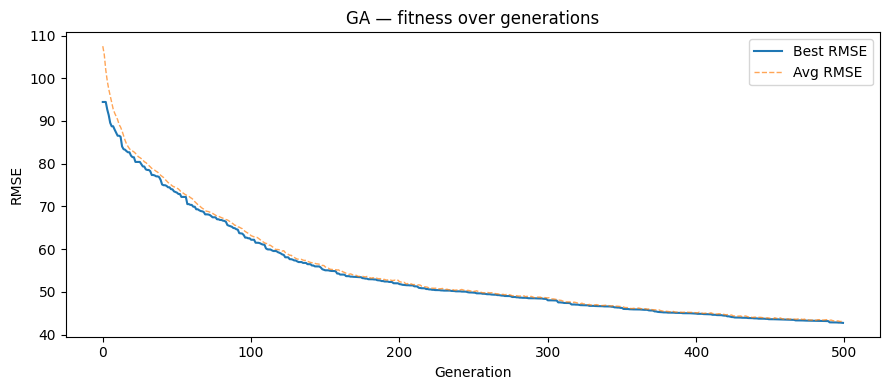

In [15]:
plot_fitness_history(history, avg_history)

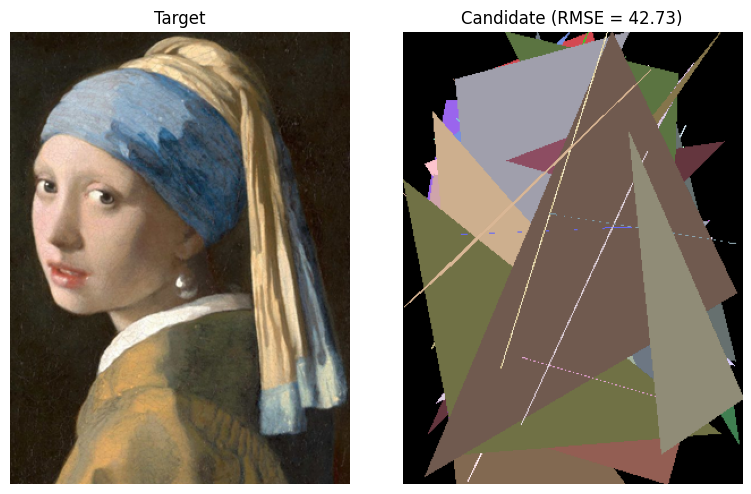

In [16]:
best.show()

<h3 id="chapter4.4" style="color:#89AC76;">4.4 GA Loop with Grid Search</h3>

In [14]:
#  Define the grid search
GRID = {
    'population_size'  : [20, 50, 100],
    'mutation_rate'    : [0.005, 0.01, 0.05],
    'crossover_rate'   : [0.7, 0.9, 1.0],
    'selection_method' : ['rank', 'roulette'],
}

GS_GENERATIONS = 500   # generations per run
GS_REPEATS     = 5     # independent runs per combination

# Fixed params
GS_FIXED = dict(
    sigma_vertex = 0.05,
    sigma_colour = 10,
    elitism_n    = 2,
    verbose      = False,
)

In [15]:
#  Grid search runner
def run_grid_search(grid, gs_generations, gs_repeats, fixed_params, n_jobs_ga=1):
    """
    Exhaustive grid search over GA hyperparameters.

    For each combination of parameters in `grid`, the GA is run
    `gs_repeats` times. The mean and std of the best RMSE across
    repeats are recorded. Results are returned sorted by mean RMSE
    (ascending — lower is better).

    Parameters
    ----------
    grid          : dict[str, list]  — parameter name -> list of values to try
    gs_generations: int              — number of generations per run
    gs_repeats    : int              — independent runs per combination
    fixed_params  : dict             — parameters held constant
    n_jobs_ga     : int              — parallel workers inside each GA run.
                                       Keep at 1 if the outer grid loop is
                                       itself parallelised to avoid nesting.

    Returns
    -------
    results : list[dict] — each entry has 'params', 'mean_rmse', 'std_rmse', 'all_rmse'
    """
    keys   = list(grid.keys())
    values = list(grid.values())
    combos = list(product(*values))

    print(f"Grid search: {len(combos)} combinations x {gs_repeats} repeats "
          f"= {len(combos) * gs_repeats} total runs\n")

    results = []

    for combo in tqdm(combos, desc='Grid search'):
        params = dict(zip(keys, combo))

        run_rmses = []
        for _ in range(gs_repeats):
            best_sol, _, _ = genetic_algorithm(
                n_generations = gs_generations,
                n_jobs        = n_jobs_ga,
                **params,
                **fixed_params,
            )
            run_rmses.append(get_fitness(best_sol))

        results.append({
            'params'    : params,
            'mean_rmse' : float(np.mean(run_rmses)),
            'std_rmse'  : float(np.std(run_rmses)),
            'all_rmse'  : run_rmses,
        })

    results.sort(key=lambda x: x['mean_rmse'])
    return results

In [16]:
#  Results display helpers
def print_grid_search_results(results, top_n=10):
    """Prints a ranked table of the top_n combinations."""
    print(f"{'Rank':<5} {'Mean RMSE':>10} {'Std':>8}   Parameters")
    print("-" * 70)
    for rank, r in enumerate(results[:top_n], 1):
        param_str = ", ".join(f"{k}={v}" for k, v in r['params'].items())
        print(f"{rank:<5} {r['mean_rmse']:>10.4f} {r['std_rmse']:>8.4f}   {param_str}")


def plot_grid_search_results(results, top_n=15):
    """Bar chart of mean RMSE for the top_n combinations."""
    top     = results[:top_n]
    labels  = ["\n".join(f"{k}={v}" for k, v in r['params'].items()) for r in top]
    means   = [r['mean_rmse'] for r in top]
    stds    = [r['std_rmse']  for r in top]

    fig, ax = plt.subplots(figsize=(max(10, top_n * 0.9), 5))
    bars = ax.bar(range(top_n), means, yerr=stds, capsize=4,
                  color='#89AC76', edgecolor='black', linewidth=0.6)
    ax.set_xticks(range(top_n))
    ax.set_xticklabels(labels, fontsize=7)
    ax.set_ylabel('Mean RMSE')
    ax.set_title(f'Grid Search — Top {top_n} Combinations')
    ax.bar_label(bars, fmt='%.3f', fontsize=7, padding=3)
    plt.tight_layout()
    plt.show()

Grid search: 54 combinations × 5 repeats = 270 total runs



Grid search: 100%|██████████| 54/54 [11:27:35<00:00, 763.99s/it]   


Rank   Mean RMSE      Std   Parameters
----------------------------------------------------------------------
1        40.0667   1.3687   population_size=100, mutation_rate=0.01, crossover_rate=1.0, selection_method=rank
2        40.1549   2.0258   population_size=100, mutation_rate=0.005, crossover_rate=1.0, selection_method=rank
3        40.8752   1.1895   population_size=100, mutation_rate=0.01, crossover_rate=0.9, selection_method=rank
4        41.6288   1.4953   population_size=100, mutation_rate=0.01, crossover_rate=0.7, selection_method=rank
5        42.0555   2.5585   population_size=100, mutation_rate=0.05, crossover_rate=0.9, selection_method=rank
6        42.3616   0.9350   population_size=100, mutation_rate=0.005, crossover_rate=0.9, selection_method=rank
7        42.3692   2.1501   population_size=100, mutation_rate=0.05, crossover_rate=1.0, selection_method=rank
8        42.5066   0.9186   population_size=100, mutation_rate=0.005, crossover_rate=0.7, selection_method=rank

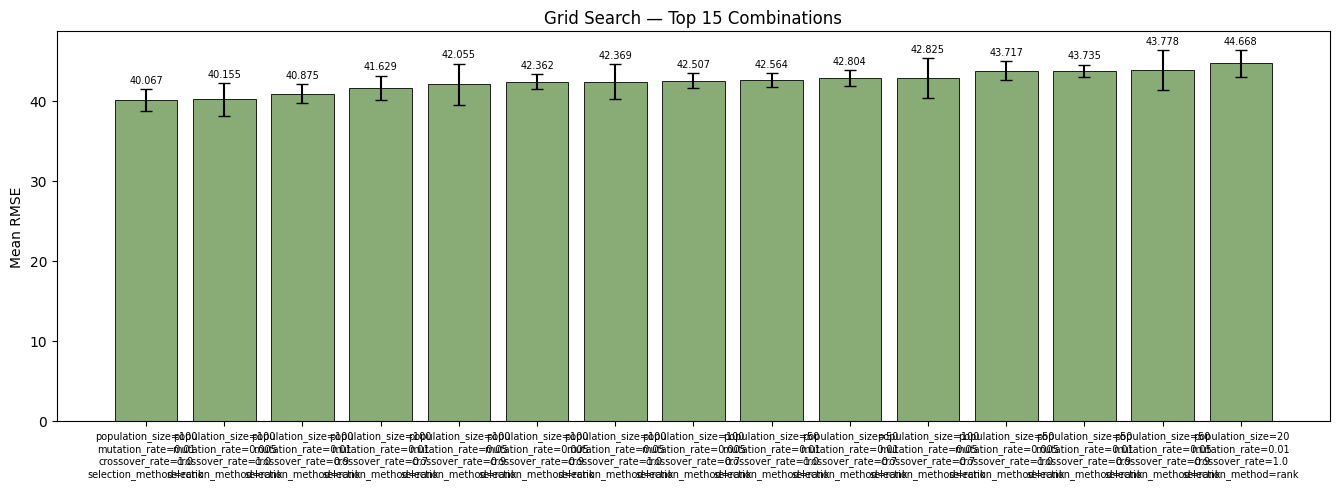

In [17]:
gs_results = run_grid_search(
    grid          = GRID,
    gs_generations= GS_GENERATIONS,
    gs_repeats    = GS_REPEATS,
    fixed_params  = GS_FIXED,
)

print_grid_search_results(gs_results, top_n=10)
plot_grid_search_results(gs_results, top_n=15)

Best parameters found: {'population_size': 100, 'mutation_rate': 0.01, 'crossover_rate': 1.0, 'selection_method': 'rank'}
Gen    0 | best RMSE: 88.0246 | avg RMSE: 106.2418
Gen   50 | best RMSE: 66.9751 | avg RMSE: 68.0497
Gen  100 | best RMSE: 58.8417 | avg RMSE: 59.5410
Gen  150 | best RMSE: 53.0480 | avg RMSE: 54.0205
Gen  200 | best RMSE: 48.6971 | avg RMSE: 49.2126
Gen  250 | best RMSE: 45.7720 | avg RMSE: 46.2994
Gen  300 | best RMSE: 44.2661 | avg RMSE: 44.6511
Gen  350 | best RMSE: 42.8623 | avg RMSE: 43.2523
Gen  400 | best RMSE: 42.1045 | avg RMSE: 42.4211
Gen  450 | best RMSE: 41.4361 | avg RMSE: 41.8042
Gen  499 | best RMSE: 41.0468 | avg RMSE: 41.3348

Finished. Best RMSE: 41.0339


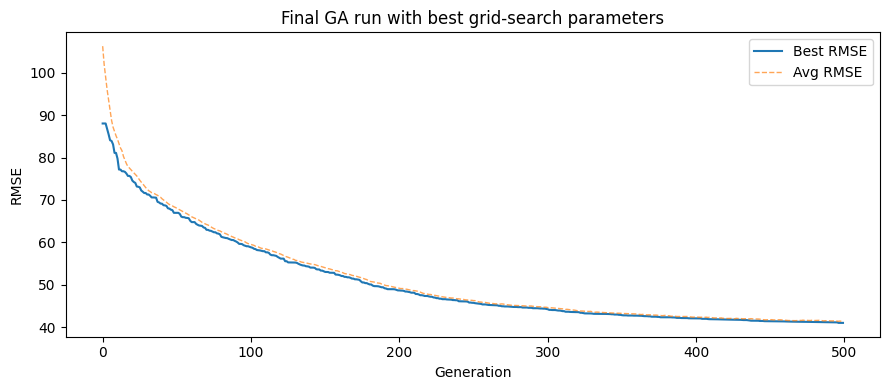

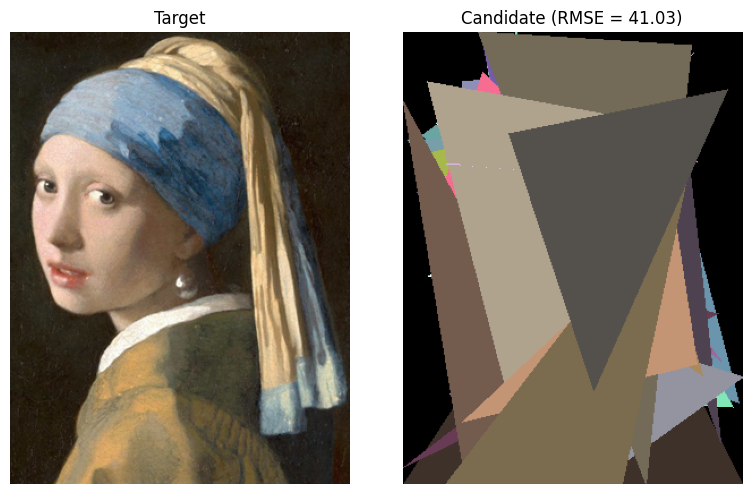

In [18]:
# Final run with best parameters found
best_params = gs_results[0]['params']
print("Best parameters found:", best_params)

best_final, history_final, avg_history_final = genetic_algorithm(
    n_generations = 500,          
    **best_params,
    **{k: v for k, v in GS_FIXED.items() if k != 'verbose'},  # exclude verbose from GS_FIXED
    verbose       = True,
    verbose_every = 50,
)


plot_fitness_history(history_final, avg_history_final,
                     title='Final GA run with best grid-search parameters')
best_final.show()

<span style="color:#BA8E23;">

### <h2><strong>CONFIRM IF IS DONE - UPDATE MAIN</strong></h2>
1. **Hybrid GA + Local Search (Hill Climbing or CMA-ES) - ANDRÉ** - CONFIRMAR SE ESTÁ
	- ran Hill Climbing as a local search after the GA converged, using the GA's best solution as the starting point.

2. **Adaptive mutation - AFONSO**
Static mutation is a bottleneck.
Use:
	- high mutation early
	- low mutation late
	- per‑triangle mutation rates

3. **Multiple operators per category - MARCO** 
	- 3 selection methods (2 - WHICH IS APPLIED NOW !!)
	- 3 crossover operators (1)
	- 3 mutation operators (1)

### <h2><strong>TOP PRIORITY</strong></h2>
1. **Fitness sharing (diversity preservation)**
- a) **Distance function**
 L2 on raw repr. array (100 triangles x 10 genes = 1000-dim vector)np.linalg.norm(a - b <br>
- b) **Sharing function**
sh(d) = 1 - (d/sigma)^a ~
	if d < sigma, 
	else 0 a=1 is linear (simplest) sigma_share to tune 
- c) **Shared fitness** 
niche = sum(sh(d(i,j))) for all j in population shared_f = raw_f * niche selection uses shared_f <br>

### <h2><strong>MEDIUM PRIORITY</strong></h2>
1. **Smarter initialization**
- Sample triangle colours from target pixels
- Cuts early RMSE immediately

2. **Diversity measurement**
Track avg pairwise distance per gen
Diagnose when sharing is helping


### <h2><strong>ANALYSIS AND REPORTING </strong></h2>
1. **Wilcoxon statistical tests with a tournament structure**<br>
Use Wilcoxon signed-rank tests to determine which configuration was statistically significantly better, then ran a tournament-style elimination comparing the winner sequentially against challengers.

2. **Search space size**
Frame as continuous space
Show problem awareness


</span>